# Week 6 — Pandas Lab

Razvan-Stefan Jipa

10 November 2026

### D1. A Series

In [1]:
# D1
import pandas as pd
values = pd.Series([87, 120, 45])
print(values)
print(values.max())


0     87
1    120
2     45
dtype: int64
120


### D2. A DataFrame from a dict

In [2]:
# D2
df = pd.DataFrame({
    "label": ["R-001", "R-002", "R-003"],
    "value": [87, 120, 45],
    "limit": [100, 100, 100]
})
print(df)
print(df.shape)


   label  value  limit
0  R-001     87    100
1  R-002    120    100
2  R-003     45    100
(3, 3)


### D3. Read a whole file with `read_csv()`

In [3]:
# D3
df = pd.read_csv("records_sample.csv")
print(df)
print(df.dtypes)


   label  value  limit
0  R-001     87    100
1  R-002    120    100
2  R-003     45    100
3  R-004     93    100
4  R-005    101    100
5  R-006     60    100
label    object
value     int64
limit     int64
dtype: object


### D4. Add a column, without a loop

In [4]:
# D4
df["percent"] = (df["value"] / df["limit"]) * 100
print(df)


   label  value  limit  percent
0  R-001     87    100     87.0
1  R-002    120    100    120.0
2  R-003     45    100     45.0
3  R-004     93    100     93.0
4  R-005    101    100    101.0
5  R-006     60    100     60.0


### D5. `iloc` and `loc`

In [5]:
# D5
print(df.iloc[0]["label"])
print(df.loc[2, "value"])


R-001
45


### D6. Selecting columns

In [6]:
# D6
print(df["label"])
print(df[["label", "percent"]])


0    R-001
1    R-002
2    R-003
3    R-004
4    R-005
5    R-006
Name: label, dtype: object
   label  percent
0  R-001     87.0
1  R-002    120.0
2  R-003     45.0
3  R-004     93.0
4  R-005    101.0
5  R-006     60.0


### D7. Filter rows with a condition

In [7]:
# D7
over_limit = df[df["percent"] >= 100]
print(over_limit)
print(len(over_limit))


   label  value  limit  percent
1  R-002    120    100    120.0
4  R-005    101    100    101.0
2


### D8. Combine conditions with `&` and `|`

In [8]:
# D8
print(df[(df["percent"] >= 90) & (df["percent"] < 100)])
print(df[(df["percent"] < 50) | (df["percent"] > 110)])


   label  value  limit  percent
3  R-004     93    100     93.0
   label  value  limit  percent
1  R-002    120    100    120.0
2  R-003     45    100     45.0


### D9. Sort

In [9]:
# D9
print(df.sort_values("percent", ascending=False))


   label  value  limit  percent
1  R-002    120    100    120.0
4  R-005    101    100    101.0
3  R-004     93    100     93.0
0  R-001     87    100     87.0
5  R-006     60    100     60.0
2  R-003     45    100     45.0


### D10. `groupby()`, `.agg()` and `value_counts()`

In [10]:
# D10
df["over"] = df["percent"] >= 100
print(df.groupby("over")["percent"].agg(["mean", "max", "min"]))
print(df["over"].value_counts())


         mean    max    min
over                       
False   71.25   93.0   45.0
True   110.50  120.0  101.0
over
False    4
True     2
Name: count, dtype: int64


### D11. A lambda

In [11]:
# D11
double = lambda x: x * 2
print(double(21))

def double_def(x):
    return x * 2

print(double_def(21))


42
42


### D12. `.apply()` with a lambda

In [12]:
# D12
df["status"] = df["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(df[["label", "status"]])
print(df["status"].value_counts())


   label      status
0  R-001          OK
1  R-002  OVER LIMIT
2  R-003          OK
3  R-004     WARNING
4  R-005  OVER LIMIT
5  R-006          OK
status
OK            3
OVER LIMIT    2
WARNING       1
Name: count, dtype: int64


### D13. Summarise and save

In [13]:
# D13
print(df.describe())
df.to_csv("records_report.csv", index=False)


            value  limit     percent
count    6.000000    6.0    6.000000
mean    84.333333  100.0   84.333333
std     27.463916    0.0   27.463916
min     45.000000  100.0   45.000000
25%     66.750000  100.0   66.750000
50%     90.000000  100.0   90.000000
75%     99.000000  100.0   99.000000
max    120.000000  100.0  120.000000


### D14. A first chart

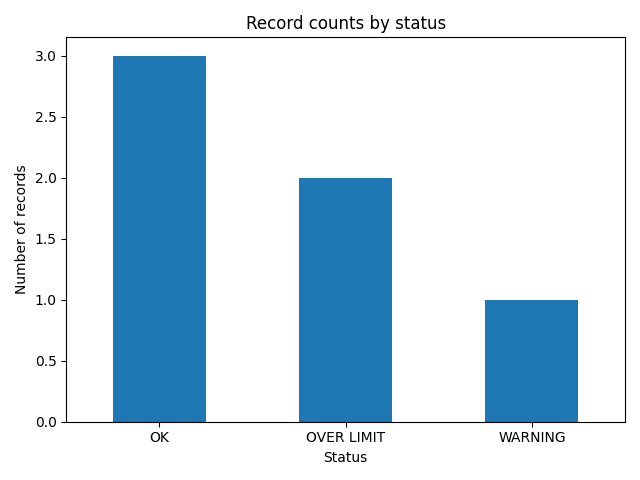

In [14]:
# D14
import matplotlib.pyplot as plt

df["status"].value_counts().plot(kind="bar")
plt.title("Record counts by status")
plt.xlabel("Status")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("status_counts.png")
plt.show()
plt.close()


### C1. Load, filter, sort and save

In [15]:
# C1
challenge_df = pd.read_csv("records_sample.csv")
challenge_df["percent"] = (challenge_df["value"] / challenge_df["limit"]) * 100
challenge_df["status"] = challenge_df["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
over_limit = challenge_df[challenge_df["status"] == "OVER LIMIT"]
over_limit = over_limit.sort_values("percent", ascending=False)
over_limit.to_csv("over_limit.csv", index=False)
print(over_limit)


   label  value  limit  percent      status
1  R-002    120    100    120.0  OVER LIMIT
4  R-005    101    100    101.0  OVER LIMIT


### C2. Average per status

In [16]:
# C2
print(df.groupby("status")["percent"].mean().round(1))


status
OK             64.0
OVER LIMIT    110.5
WARNING        93.0
Name: percent, dtype: float64


### Completed mini-project: Cyber Security

`template.py` reads `cyber_records.csv` and completes the Excellent tier. The data is made-up practice data, not real login records. The lab's status thresholds are used exactly: 100% or more is OVER LIMIT, 90% or more is WARNING, and anything lower is OK. These are exercise thresholds, not a real security detection policy.

Hand check: 95 failed logins / 100 total attempts × 100 = 95%, so 10.0.0.2 has status WARNING. 100 / 100 × 100 = 100%, so 10.0.0.3 has status OVER LIMIT.


## Week 6 cheat sheet notes

A Series stores one column of data and a DataFrame stores a table with rows and columns. pd.read_csv() loads a CSV file, .shape shows the number of rows and columns, and .dtypes shows the data types. I can calculate a new column without a loop, such as dividing value by limit and multiplying by 100 to get a percentage. Single brackets select one column and double brackets select several columns. .iloc selects rows by position, while .loc selects rows and columns by their labels. A condition inside brackets filters rows, and I use & for both conditions or | for either condition, with brackets around each condition. .sort_values() sorts the data, and ascending=False puts the biggest values first. .groupby() groups matching values so I can calculate summaries such as the mean, maximum and minimum. .value_counts() counts how often each value appears. A lambda is a small function with one expression, and .apply() uses a function on each value in a column. A normal def function is better when the code needs several steps. .describe() gives a summary of the number columns, .to_csv(index=False) saves the table without an extra index column, and .plot(kind="bar") creates a bar chart that I can save with plt.savefig().

## Handwritten cheat sheet